Tutorial: Timoshenko beam benchmarks with BeamC and BeamLR
===

Static deflections and natural frequencies of Timoshenko cantilevers computed
with the two beam elements of pyfe3d and compared with published values:

- `BeamC`: consistent (interdependent) interpolation, cubic deflection and
  quadratic rotation that depend on the shear parameter, such that the
  element solves the homogeneous equilibrium equations of the Timoshenko beam
  exactly;
- `BeamLR`: linear interpolation of the deflection and of the rotation,
  with reduced integration of the transverse shear;
- the Euler-Bernoulli beam, without shear deformation, as a third reference.

The references are:

- Bathe, K. J., *Finite Element Procedures*, 2nd ed., K. J. Bathe,
  Watertown, MA, 2014, Section 1.2, Eq. (1.2) and Fig. 1.2;
- Petyt, M., *Introduction to Finite Element Vibration Analysis*, 2nd ed.,
  Cambridge University Press, 2010,
  [doi:10.1017/CBO9780511761195](https://doi.org/10.1017/CBO9780511761195),
  Example 3.10 and Table 3.6.

The models are those of `tests/test_timoshenko_beam_literature.py` and
`tests/test_beamc_timoshenko_shape_functions.py`, imported below.

In [1]:
import os
import sys
sys.path.insert(0, os.path.join('..', '..', 'tests'))

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyfe3d.beamprop import BeamProp
from test_timoshenko_beam_literature import (bathe_prop, cantilever_tip,
                                             petyt_coefficients)
import test_beamc_timoshenko_shape_functions as sf

Static deflection of a cantilever with shear deformation
---

Bathe (2014), Section 1.2, Fig. 1.2: cantilever of length $L = 28$ cm,
rectangular cross section of height $h = 6$ cm and thickness $t = 0.4$ cm,
$E = 2 \times 10^7$ N/cm$^2$, $\nu = 0.3$, tip force $W = 1000$ N. Eq. (1.2)
gives the tip deflection with the bending and the shear contributions, with
the shear correction factor $5/6$:

$$
\delta = \frac{W L^3}{3 E I} + \frac{W L}{\frac{5}{6} A G} = 0.053 \text{ cm}
$$

The function `bathe_prop()` of the test puts the factor $5/6$ in `prop.G`.
The Euler-Bernoulli deflection is the first term only.

In [2]:
L = 28. # cm
W = 1000. # N
prop = bathe_prop()
delta_bending = W*L**3/(3*prop.E*prop.Izz)
delta_ref = delta_bending + W*L/(prop.A*prop.G) # Eq. (1.2) of Bathe (2014)
delta_published = 0.053 # cm

print('%-28s %12s %10s' % ('model', 'delta [cm]', 'error [%]'))
print('%-28s %12.7f %10s' % ('Bathe (2014), published', delta_published, ''))
print('%-28s %12.7f %10s' % ('Bathe (2014), Eq. (1.2)', delta_ref, ''))
print('%-28s %12.7f %10.3f' % ('Euler-Bernoulli', delta_bending,
                               100*(delta_bending - delta_ref)/delta_ref))
for name, n in [('BeamC', 1), ('BeamC', 3), ('BeamLR', 1), ('BeamLR', 4),
                ('BeamLR', 16), ('BeamLR', 100)]:
    delta = W*cantilever_tip(name, prop, L, n)[0]
    print('%-28s %12.7f %10.3f' % ('%s, %d element(s)' % (name, n), delta,
                                   100*(delta - delta_ref)/delta_ref))

delta = W*cantilever_tip('BeamC', prop, L, 1)[0]
print()
print('check: one BeamC element against Eq. (1.2), relative difference %.1e'
      % abs(delta/delta_ref - 1))
print('check: one BeamC element rounded to the published two digits: %.3f cm'
      % delta)

model                          delta [cm]  error [%]
Bathe (2014), published         0.0530000           
Bathe (2014), Eq. (1.2)         0.0526348           
Euler-Bernoulli                 0.0508148     -3.458
BeamC, 1 element(s)             0.0526348     -0.000
BeamC, 3 element(s)             0.0526348      0.000
BeamLR, 1 element(s)            0.0399311    -24.136
BeamLR, 4 element(s)            0.0518408     -1.508
BeamLR, 16 element(s)           0.0525852     -0.094
BeamLR, 100 element(s)          0.0526335     -0.002

check: one BeamC element against Eq. (1.2), relative difference 2.2e-16
check: one BeamC element rounded to the published two digits: 0.053 cm


One `BeamC` element gives Eq. (1.2) to round-off; the Euler-Bernoulli beam
misses the shear deflection, 3.6 % of the bending deflection of this beam
($L/h \approx 4.7$).
`BeamLR` converges with the number of elements. The convergence is plotted
below for Bathe's cantilever and for a cantilever as long as deep, $L = h$,
where the shear deflection is larger than the bending one (the second model of
the test, `test_deep_cantilever_shear_deflection`).

Bathe (2014), L/h = 4.7: BeamLR error 2.4e-01 6.0e-02 1.5e-02 3.8e-03 9.4e-04 2.4e-04 5.9e-05 1.5e-05
Bathe (2014), L/h = 4.7: BeamC  error 2.2e-16 1.3e-15 1.9e-14 4.0e-14 2.5e-14 2.1e-13 9.4e-14 6.1e-13
Bathe (2014), L/h = 4.7: BeamLR order between the last two meshes 2.00
deep cantilever, L/h = 1: BeamLR error 1.5e-01 3.8e-02 9.5e-03 2.4e-03 5.9e-04 1.5e-04 3.7e-05 9.2e-06
deep cantilever, L/h = 1: BeamC  error 1.1e-16 0.0e+00 2.2e-16 1.6e-15 4.4e-16 6.1e-14 2.3e-13 5.2e-14
deep cantilever, L/h = 1: BeamLR order between the last two meshes 2.00


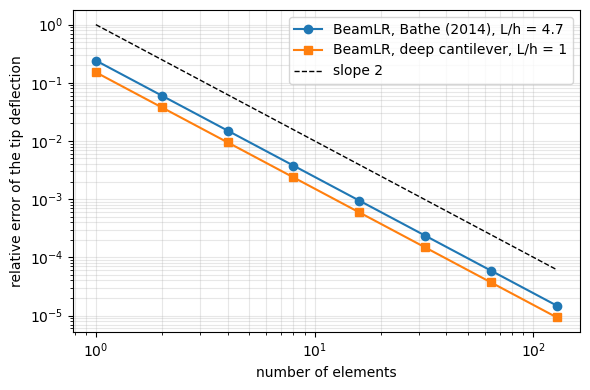

In [3]:
def deep_prop():
    E, nu, h = 1., 0.3, 1.
    p = BeamProp()
    p.A = h*h
    p.E = E
    p.G = E/(2*(1 + nu))
    p.Izz = p.Iyy = h**4/12
    p.J = 2*h**4/12
    return p

cases = {
    'Bathe (2014), L/h = 4.7': (bathe_prop(), 28.),
    'deep cantilever, L/h = 1': (deep_prop(), 1.),
}
ns = np.array([1, 2, 4, 8, 16, 32, 64, 128])
fig, ax = plt.subplots(figsize=(6, 4))
for (label, (p, Lc)), marker in zip(cases.items(), ['o', 's']):
    ref = Lc**3/(3*p.E*p.Izz) + Lc/(p.A*p.G)
    err_lr = [abs(cantilever_tip('BeamLR', p, Lc, n)[0]/ref - 1) for n in ns]
    err_c = [abs(cantilever_tip('BeamC', p, Lc, n)[0]/ref - 1) for n in ns]
    ax.loglog(ns, err_lr, marker=marker, label='BeamLR, ' + label)
    print('%s: BeamLR error %s' % (label, ' '.join('%.1e' % e for e in err_lr)))
    print('%s: BeamC  error %s' % (label, ' '.join('%.1e' % e for e in err_c)))
    print('%s: BeamLR order between the last two meshes %.2f'
          % (label, np.log(err_lr[-2]/err_lr[-1])/np.log(2)))
ax.loglog(ns, 1./ns**2, 'k--', lw=1, label='slope 2')
ax.set_xlabel('number of elements')
ax.set_ylabel('relative error of the tip deflection')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

`BeamC` is exact with any number of elements (errors at round-off, not
plotted on the logarithmic scale); `BeamLR` converges quadratically.

The shear parameter of BeamC
---

With $\phi = 12 E I/(G A L^2)$, the shape functions of `BeamC` depend on
$\alpha = -\phi$ and $\beta = 1/(1 - \alpha) = 1/(1 + \phi)$, see the notes of
`BeamC`. With this sign they solve the homogeneous equilibrium equations of
the Timoshenko beam, the same solution as Eq. (3.236) of Petyt (2010), whose
denominator $1 + 3\beta_P$, with $\beta_P = E I/(\kappa A G a^2)$ and
$a = L/2$, is $1 + \phi$. Eq. (21) of Luo (2008), the source of the shape
functions (Luo, Y., An Efficient 3D Timoshenko Beam Element with Consistent
Shape Functions, Adv. Theor. Appl. Mech., 1(3), 95-106, 2008), gives
$\alpha$ with the positive sign, which `BeamC` used before version 0.11.0.

The effect of the sign is shown with the shape functions of
`tests/test_beamc_timoshenko_shape_functions.py`, written there for any
$\alpha$: the bending and shear stiffness matrix of one element,

$$
\boldsymbol{K}_e = \int_0^L \left( E I \boldsymbol{S}_{r_z,x}^\top \boldsymbol{S}_{r_z,x}
       + G A \boldsymbol{S}_\gamma^\top \boldsymbol{S}_\gamma \right) dx, \qquad
\gamma_{xy} = v_{,x} - r_z
$$

is integrated with a 6-point Gauss quadrature, and the tip deflection of a
cantilever with one element under a unit tip force is computed for
$\alpha = -\phi$, $0$ and $+\phi$ (the square cross section $0.3 \times 0.3$,
$E = 1$, $\nu = 0.3$, $L = 1$ of that test).

In [4]:
def element_matrix(alpha, EI, GA):
    L = sf.L
    K = np.zeros((12, 12))
    points, weights = np.polynomial.legendre.leggauss(6)
    h = 1.e-6
    for p, w in zip(points, weights):
        xi = (p + 1)/2
        Nu, Nv, Nw, Nrx, Nry, Nrz, Sv_x, Sw_x = sf.shape_functions(xi, alpha)
        # NOTE r_z is quadratic in xi: the central difference is exact
        Srz_x = (sf.shape_functions(xi + h, alpha)[5]
                - sf.shape_functions(xi - h, alpha)[5])/(2*h*L)
        gamma = Sv_x - Nrz
        K += w*L/2*(EI*np.outer(Srz_x, Srz_x) + GA*np.outer(gamma, gamma))
    return K

def one_element_tip(alpha, EI, GA):
    tip = [7, 11] # v and r_z of node 2
    K = element_matrix(alpha, EI, GA)
    return np.linalg.solve(K[np.ix_(tip, tip)], [1., 0.])[0]

p = sf.get_prop()
EI, GA = p.E*p.Izz, p.G*p.A
phi = 12*EI/(GA*sf.L**2)
exact = sf.L**3/(3*EI) + sf.L/GA
print('phi = %.4f' % phi)
print('Euler-Bernoulli %.3f, Timoshenko (exact) %.3f' % (sf.L**3/(3*EI), exact))
for label, alpha in [('alpha = -phi', -phi), ('alpha = 0', 0.),
                     ('alpha = +phi', +phi)]:
    tip = one_element_tip(alpha, EI, GA)
    print('%-13s tip deflection %.3f, error %+.2f %%'
          % (label, tip, 100*(tip/exact - 1)))
tip, _ = sf.cantilever(1)
print('BeamC, one element: %.3f, relative difference %.1e'
      % (tip[0], abs(tip[0]/exact - 1)))

phi = 0.2340
Euler-Bernoulli 493.827, Timoshenko (exact) 522.716
alpha = -phi  tip deflection 522.716, error -0.00 %
alpha = 0     tip deflection 493.827, error -5.53 %
alpha = +phi  tip deflection 429.073, error -17.91 %
BeamC, one element: 522.716, relative difference 6.7e-16


With $\alpha = 0$ the interpolation is the cubic Hermite interpolation of the
Euler-Bernoulli beam, with no shear strain. With $\alpha = +\phi$ the element
of this beam, $L/b = 3.3$, is even stiffer than the Euler-Bernoulli beam,
although the shear deformation can only make the beam more flexible. Over a
range of slenderness, only $\alpha = -\phi$ gives the exact deflection:

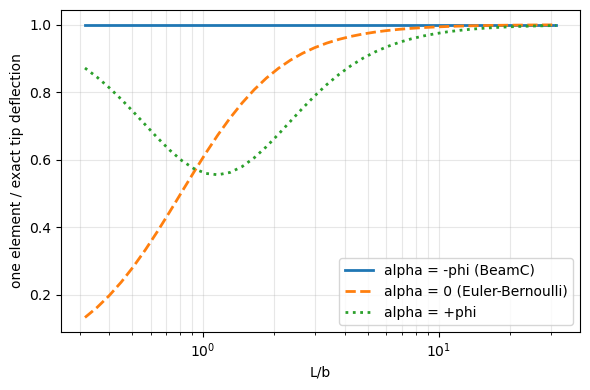

check: alpha = -phi exact for all L/b, max |ratio - 1| = 3.4e-11


In [5]:
# NOTE sf.shape_functions() is written for the length sf.L = 1: the length is
#      kept and the side b of the square cross section varies
slenderness = np.logspace(-0.5, 1.5, 40) # L/b
ratios = {'alpha = -phi (BeamC)': [], 'alpha = 0 (Euler-Bernoulli)': [],
          'alpha = +phi': []}
for Lb in slenderness:
    b = sf.L/Lb
    EI_b, GA_b = p.E*b**4/12, p.G*b**2
    phi_b = 12*EI_b/(GA_b*sf.L**2)
    exact_b = sf.L**3/(3*EI_b) + sf.L/GA_b
    for key, alpha in zip(ratios, (-phi_b, 0., phi_b)):
        ratios[key].append(one_element_tip(alpha, EI_b, GA_b)/exact_b)
fig, ax = plt.subplots(figsize=(6, 4))
for (key, values), ls in zip(ratios.items(), ['-', '--', ':']):
    ax.semilogx(slenderness, values, ls, lw=2, label=key)
ax.set_xlabel('L/b')
ax.set_ylabel('one element / exact tip deflection')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()
print('check: alpha = -phi exact for all L/b, max |ratio - 1| = %.1e'
      % np.abs(np.array(ratios['alpha = -phi (BeamC)']) - 1).max())

Natural frequencies with shear deformation and rotary inertia
---

Petyt (2010), Example 3.10 and Table 3.6: cantilever with radius of gyration
$r_z/L = 0.08$, shear coefficient $\kappa = 2/3$ and $E/G = 8/3$, with shear
deformation and rotary inertia, in terms of the frequency coefficients
$\lambda = \omega \sqrt{\rho A L^4/(E I)}$. One element with the same shape
functions and consistent mass matrix as `BeamC` gives $3.322$ and $26.569$
(p. 99-100); Table 3.6 lists the exact coefficients and the errors of three
elements for $r_z/L = 0.08$ and $0.02$. The function `petyt_coefficients()`
of the test assembles the cantilever and keeps the bending in the $xy$ plane.

In [6]:
one = petyt_coefficients('BeamC', 0.08, 1, num_modes=2)
print('one BeamC element, r_z/L = 0.08')
print('%6s %10s %10s' % ('mode', 'Petyt', 'BeamC'))
for i, (ref, c) in enumerate(zip([3.322, 26.569], one)):
    print('%6d %10.3f %10.3f' % (i + 1, ref, c))
print('check: max |difference| %.1e (published with three decimals)'
      % np.abs(one - [3.322, 26.569]).max())

table_3_6 = {
    0.08: ([3.284, 15.488, 34.301], [0.12, 2.47, 8.80]),
    0.02: ([3.500, 21.353, 57.474], [0.02, 0.59, 2.37]),
}
for rz_L, (exact, errors) in table_3_6.items():
    coef = petyt_coefficients('BeamC', rz_L, 3)
    err = 100*(coef - exact)/np.array(exact)
    print()
    print('three BeamC elements, r_z/L = %.2f' % rz_L)
    print('%6s %10s %10s %14s %14s' % ('mode', 'exact', 'BeamC',
                                       'error Petyt %', 'error BeamC %'))
    for i in range(3):
        print('%6d %10.3f %10.3f %14.2f %14.2f'
              % (i + 1, exact[i], coef[i], errors[i], err[i]))

one BeamC element, r_z/L = 0.08
  mode      Petyt      BeamC
     1      3.322      3.322
     2     26.569     26.569
check: max |difference| 3.0e-04 (published with three decimals)

three BeamC elements, r_z/L = 0.08
  mode      exact      BeamC  error Petyt %  error BeamC %
     1      3.284      3.288           0.12           0.12
     2     15.488     15.871           2.47           2.47
     3     34.301     37.320           8.80           8.80

three BeamC elements, r_z/L = 0.02
  mode      exact      BeamC  error Petyt %  error BeamC %
     1      3.500      3.500           0.02           0.01
     2     21.353     21.480           0.59           0.59
     3     57.474     58.839           2.37           2.37


The Euler-Bernoulli cantilever, without shear deformation and rotary inertia,
has $\lambda = x^2$ with $x$ the roots of $\cos x \cosh x = -1$. Its
coefficients show how much the shear deformation and the rotary inertia lower
the frequencies of these deep beams. The convergence of `BeamC` and `BeamLR`
to the exact values of Table 3.6, $r_z/L = 0.08$:

Euler-Bernoulli lambda: 3.516 22.034 61.697
Petyt (2010), exact with shear and rotary inertia, r_z/L = 0.08: 3.284 15.488 34.301
BeamC, 160 elements: 3.2837 15.4885 34.3020
BeamLR, 160 elements: 3.2837 15.4893 34.3053


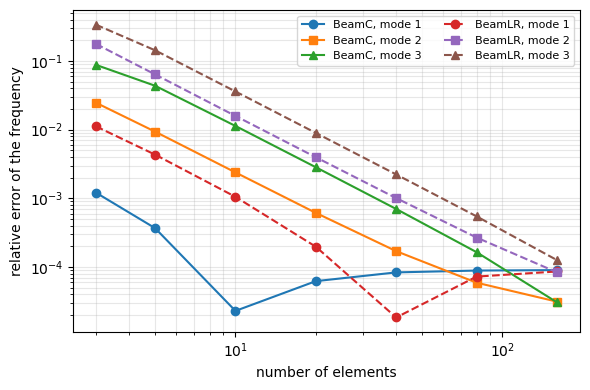

check: 160 BeamC elements against the exact values of Table 3.6, max relative difference 9.0e-05


In [7]:
f = lambda x: np.cos(x)*np.cosh(x) + 1
roots = [brentq(f, a, b) for a, b in [(1, 3), (4, 6), (7, 9)]]
lambda_eb = np.array(roots)**2
exact = np.array(table_3_6[0.08][0])
print('Euler-Bernoulli lambda: %s' % ' '.join('%.3f' % l for l in lambda_eb))
print('Petyt (2010), exact with shear and rotary inertia, r_z/L = 0.08: %s'
      % ' '.join('%.3f' % l for l in exact))

ns = np.array([3, 5, 10, 20, 40, 80, 160])
fig, ax = plt.subplots(figsize=(6, 4))
markers = ['o', 's', '^']
for name, ls in [('BeamC', '-'), ('BeamLR', '--')]:
    errs = np.array([np.abs(petyt_coefficients(name, 0.08, n)/exact - 1)
                     for n in ns])
    for mode in range(3):
        ax.loglog(ns, errs[:, mode], ls, marker=markers[mode],
                  label='%s, mode %d' % (name, mode + 1))
    print('%s, 160 elements: %s' % (name, ' '.join(
        '%.4f' % c for c in petyt_coefficients(name, 0.08, 160))))
ax.set_xlabel('number of elements')
ax.set_ylabel('relative error of the frequency')
ax.grid(True, which='both', alpha=0.3)
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()
coef = petyt_coefficients('BeamC', 0.08, 160)
print('check: 160 BeamC elements against the exact values of Table 3.6, '
      'max relative difference %.1e' % np.abs(coef/exact - 1).max())

Three `BeamC` elements reproduce the errors of Table 3.6 within their
rounding (the exact values have three decimals and the errors two). Both
elements converge to the exact values of Table 3.6; the difference left with
160 elements is within the rounding of the three published decimals, which
is where the errors of the plot level off. `BeamC`
starts much closer, because its interpolation solves the static equilibrium
equations; the error left comes from the interpolation of the inertia
forces.

Summary
---

| benchmark | reference | pyfe3d |
|---|---|---|
| cantilever tip deflection with shear | Bathe (2014), Eq. (1.2), 0.053 cm | one `BeamC`: Eq. (1.2) to round-off; `BeamLR`: second-order convergence |
| frequency coefficients, one element | Petyt (2010), Example 3.10: 3.322, 26.569 | one `BeamC`: the same three decimals |
| errors of three elements | Petyt (2010), Table 3.6 | three `BeamC`: the same errors, within their rounding |
| exact frequency coefficients | Petyt (2010), Table 3.6 | `BeamC` and `BeamLR` converge to them |